 # DMRG/MPS Study of the Transverse-Field Ising Chain



 This notebook reproduces the 2026–2027 Quimb tutorial's open-chain TFIM field plot and extends the study with controlled bond-dimension, chain-length, entanglement, correlation, critical-exponent, and exact-diagonalization stress tests. The verbatim instructor notebook is preserved in `notebooks/tutorial_source/`.



 The 51-point scan retains $L=40$, $J=1$, the tutorial field grid $b_x \in [0,1]$, and its bond-dimension schedule `bond_dims=[8, 16, 32, 64]`. Quimb's MPS-native `local_expectation` evaluates the same one-site Pauli-$Z$ expectation as the source contraction while avoiding full-network contraction errors on Windows. The field plot shows both the fixed-Hamiltonian Pfeuty reference and the literal analytic expression coded in the course cell.

 ## 1. Execution environment and run identity



 The first code cell records the Python interpreter, machine hardware visible to the process, package versions, and configured preflight guardrails. Absolute user paths are omitted from the published JSON record.

In [1]:
from pathlib import Path
import csv, json, os, platform, sys, time, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import quimb as qu
import quimb.tensor as qtn

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "tutorial_faithful"
try:
    EXECUTABLE_LABEL = str(Path(sys.executable).resolve().relative_to(ROOT.resolve()))
except ValueError:
    EXECUTABLE_LABEL = Path(sys.executable).name
RESULTS.mkdir(parents=True, exist_ok=True)
PROCESS = psutil.Process()

def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

environment = {
    "timestamp_local": time.strftime("%Y-%m-%d %H:%M:%S %z"),
    "python": sys.version,
    "python_executable": EXECUTABLE_LABEL,
    "architecture": platform.architecture()[0],
    "platform": platform.platform(),
    "cpu_model": platform.processor() or "not reported by platform.processor()",
    "physical_cpus": psutil.cpu_count(logical=False),
    "logical_cpus": psutil.cpu_count(logical=True),
    "installed_ram_gib": round(psutil.virtual_memory().total / 2**30, 2),
    "available_ram_gib_at_start": round(psutil.virtual_memory().available / 2**30, 2),
    "gpu_model": "Not recorded; Quimb uses the NumPy CPU backend in this study.",
    "packages": {p: package_version(p) for p in ["numpy", "scipy", "matplotlib", "pandas", "psutil", "quimb"]},
    "notes": "Machine-specific absolute paths are omitted from the public record.",
}
(RESULTS / "dmrg_environment_record.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print(json.dumps(environment, indent=2))

# Conservative, configurable preflight heuristic (not a measured peak-memory guarantee).
MAX_ESTIMATED_GIB = 0.60 * psutil.virtual_memory().available / 2**30
MAX_L = 200
MAX_CHI = 128
print(f"Configured heuristic preflight budget: {MAX_ESTIMATED_GIB:.2f} GiB; L cap={MAX_L}; chi cap={MAX_CHI}")


{
  "timestamp_local": "2026-11-23 10:31:42 +0100",
  "python": "3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]",
  "python_executable": ".venv\\Scripts\\python.exe",
  "architecture": "64bit",
  "platform": "Windows-10-10.0.19045-SP0",
  "cpu_model": "Intel64 Family 6 Model 186 Stepping 2, GenuineIntel",
  "physical_cpus": 12,
  "logical_cpus": 16,
  "installed_ram_gib": 15.72,
  "available_ram_gib_at_start": 4.22,
  "gpu_model": "Not recorded; Quimb uses the NumPy CPU backend in this study.",
  "packages": {
    "numpy": "2.5.5",
    "scipy": "1.18.1",
    "matplotlib": "3.11.2",
    "pandas": "3.1.1",
    "psutil": "7.2.2",
    "quimb": "1.16.0"
  },
  "notes": "Machine-specific absolute paths are omitted from the public record."
}
Configured heuristic preflight budget: 2.54 GiB; L cap=200; chi cap=128


 ## 2. Run logging and pilot calculation



 A fresh top-to-bottom run resets `dmrg_runs.csv` to avoid duplicate entries, then appends every DMRG case immediately after execution with schema-safe CSV writing. The pilot verifies that Quimb's positive-$J$ antiferromagnetic spin-$1/2$ TFIM Hamiltonian executes cleanly on this machine.

In [2]:
DMRG_RUNS_FILE = RESULTS / "dmrg_runs.csv"
DMRG_RUNS_FILE.unlink(missing_ok=True)

def append_run(row, filename="dmrg_runs.csv"):
    """Append a run record safely, expanding headers if later rows introduce new keys."""
    path = RESULTS / filename
    if not path.exists():
        with path.open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(row))
            writer.writeheader()
            writer.writerow(row)
        return

    with path.open("r", newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        old_fields = reader.fieldnames or []
        old_rows = list(reader)
    fieldnames = old_fields + [field for field in row if field not in old_fields]
    old_rows.append(row)
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(old_rows)

def run_dmrg_case(L, g, chi, J=1.0, max_sweeps=8, tolerance=1e-8, label="case"):
    started = time.perf_counter()
    before = PROCESS.memory_info().rss / 2**20
    available_gib = psutil.virtual_memory().available / 2**30
    estimated_gib = 64.0 * L * chi**2 / 2**30  # heuristic preflight only, not measured peak memory
    row = {
        "label": label, "L": L, "g": g, "J": J, "chi": chi,
        "max_sweeps": max_sweeps, "tolerance": tolerance,
        "estimated_workspace_gib": estimated_gib,
        "available_gib_before": available_gib,
        "rss_before_mib": before,
        "status": "NOT_STARTED",
        "error": "",
    }
    if L > MAX_L or chi > MAX_CHI or estimated_gib > MAX_ESTIMATED_GIB:
        row["status"] = "SKIPPED_PREFLIGHT_BUDGET"
        row["elapsed_seconds"] = 0.0
        append_run(row)
        return row, None
    try:
        # Quimb's positive j is the antiferromagnetic spin-1/2 convention used in the tutorial.
        H = qtn.MPO_ham_ising(L, j=J, bx=J * g)
        solver = qtn.DMRG2(H, bond_dims=[chi])
        solver.solve(max_sweeps=max_sweeps, tol=tolerance, verbosity=0)
        energy = float(np.real(solver.energy))
        row.update({
            "status": "COMPLETED",
            "energy": energy,
            "energy_per_site": energy / L,
            "elapsed_seconds": time.perf_counter() - started,
            "rss_after_mib": PROCESS.memory_info().rss / 2**20,
            "available_gib_after": psutil.virtual_memory().available / 2**30,
        })
        append_run(row)
        return row, solver
    except Exception as exc:
        row.update({
            "status": "ERROR",
            "error": f"{type(exc).__name__}: {exc}",
            "elapsed_seconds": time.perf_counter() - started,
            "rss_after_mib": PROCESS.memory_info().rss / 2**20,
            "available_gib_after": psutil.virtual_memory().available / 2**30,
        })
        append_run(row)
        return row, None

pilot, pilot_solver = run_dmrg_case(L=16, g=0.5, chi=8, max_sweeps=6, label="pilot")
pilot


{'label': 'pilot',
 'L': 16,
 'g': 0.5,
 'J': 1.0,
 'chi': 8,
 'max_sweeps': 6,
 'tolerance': 1e-08,
 'estimated_workspace_gib': 6.103515625e-05,
 'available_gib_before': 4.224002838134766,
 'rss_before_mib': 221.765625,
 'status': 'COMPLETED',
 'error': '',
 'energy': -5.00409690318633,
 'energy_per_site': -0.3127560564491456,
 'elapsed_seconds': 0.41053939999983413,
 'rss_after_mib': 230.07421875,
 'available_gib_after': 4.316555023193359}

 ## 3. Central longitudinal order across the field



 This reproduces the tutorial's 51-point field scan: $L=40$, $J=1$, $b_x \in [0,1]$, `bond_dims=[8, 16, 32, 64]`, and `tol=1e-6`. The plotted observable is $|m_z| = |\langle Z_{L/2} \rangle|$, evaluated via Quimb's MPS-native `local_expectation` (with a contraction fallback) to avoid full-network contraction issues on Windows.



 Both the thermodynamic Pfeuty reference for fixed $J=1$ ($[1-(2g)^2]^{1/8}$ for $g < 0.5$) and the literal expression coded in the course notebook ($\lambda = b_x/(1-b_x)$) are plotted together with the absolute-difference diagnostic.

Field 01/51: g=0.00, COMPLETED, 0.26 s
Field 02/51: g=0.02, COMPLETED, 0.35 s
Field 03/51: g=0.04, COMPLETED, 0.21 s
Field 04/51: g=0.06, COMPLETED, 0.23 s
Field 05/51: g=0.08, COMPLETED, 0.23 s
Field 06/51: g=0.10, COMPLETED, 0.31 s
Field 07/51: g=0.12, COMPLETED, 0.33 s
Field 08/51: g=0.14, COMPLETED, 0.28 s
Field 09/51: g=0.16, COMPLETED, 0.22 s
Field 10/51: g=0.18, COMPLETED, 0.19 s
Field 11/51: g=0.20, COMPLETED, 0.24 s
Field 12/51: g=0.22, COMPLETED, 0.30 s
Field 13/51: g=0.24, COMPLETED, 0.20 s
Field 14/51: g=0.26, COMPLETED, 0.20 s
Field 15/51: g=0.28, COMPLETED, 0.20 s
Field 16/51: g=0.30, COMPLETED, 0.19 s
Field 17/51: g=0.32, COMPLETED, 0.26 s
Field 18/51: g=0.34, COMPLETED, 0.27 s
Field 19/51: g=0.36, COMPLETED, 0.27 s
Field 20/51: g=0.38, COMPLETED, 0.20 s
Field 21/51: g=0.40, COMPLETED, 0.30 s
Field 22/51: g=0.42, COMPLETED, 0.25 s
Field 23/51: g=0.44, COMPLETED, 0.91 s
Field 24/51: g=0.46, COMPLETED, 1.08 s
Field 25/51: g=0.48, COMPLETED, 0.97 s
Field 26/51: g=0.50, COMP

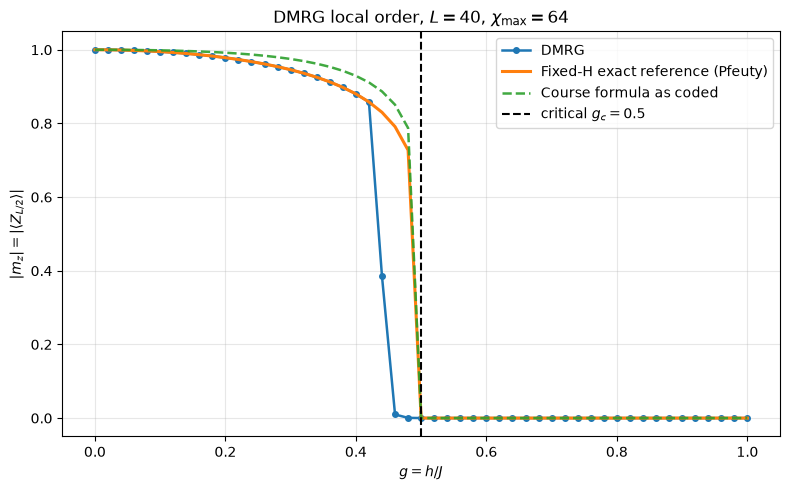

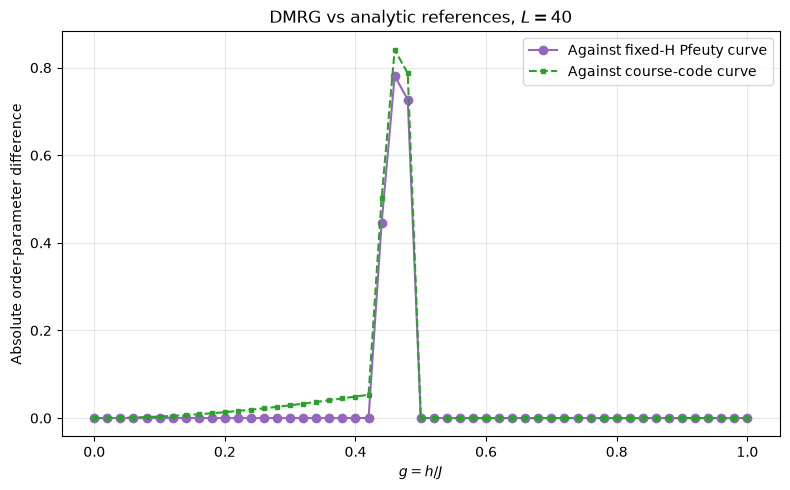

,L,g,j,bond_dims,status,error,local_Z_center,energy,elapsed_seconds,rss_before_mib,rss_after_mib,available_gib_after,m_z_exact,m_z_course_formula
46,40,0.92,1.0,"8,16,32,64",COMPLETED,,-9.769268e-08,-19.749754,0.241089,242.257812,242.257812,4.713768,0.0,0.0
47,40,0.94,1.0,"8,16,32,64",COMPLETED,,-7.448686e-09,-20.119924,0.185565,242.257812,242.257812,4.714333,0.0,0.0
48,40,0.96,1.0,"8,16,32,64",COMPLETED,,-4.536520e-08,-20.491411,0.187965,242.257812,242.257812,4.714867,0.0,0.0
49,40,0.98,1.0,"8,16,32,64",COMPLETED,,1.024028e-08,-20.864128,0.212348,242.257812,242.257812,4.776993,0.0,0.0
50,40,1.00,1.0,"8,16,32,64",COMPLETED,,6.466833e-08,-21.237996,0.208729,242.257812,242.257812,4.793430,0.0,0.0


In [3]:
L_MAG = 40
MAG_BOND_DIMS = [8, 16, 32, 64]
G_MAG = np.linspace(0.0, 1.0, 51)
Z = qu.pauli("z")
mag_rows = []
mag_path = RESULTS / "dmrg_magnetization_sweep.csv"

def measure_local_z(psi, site):
    """Evaluate <Z_site> using Quimb's MPS-native local_expectation when available."""
    if hasattr(psi, "local_expectation"):
        try:
            return float(np.real(psi.local_expectation(Z, site)))
        except (TypeError, KeyError, ValueError):
            return float(np.real(psi.local_expectation(Z, (site,))))
    psi_z = psi.gate(Z, site)
    return float(np.real(psi.H @ psi_z))

for point, g in enumerate(G_MAG, start=1):
    started = time.perf_counter()
    before_rss = PROCESS.memory_info().rss / 2**20
    row = {
        "L": L_MAG, "g": float(g), "j": 1.0,
        "bond_dims": ",".join(map(str, MAG_BOND_DIMS)),
        "status": "NOT_STARTED", "error": "",
    }
    try:
        H = qtn.MPO_ham_ising(L_MAG, j=1.0, bx=float(g))
        solver = qtn.DMRG2(H, bond_dims=MAG_BOND_DIMS)
        solver.solve(verbosity=0, tol=1e-6)
        psi = solver.state
        local_z = measure_local_z(psi, L_MAG // 2)
        row.update({
            "local_Z_center": local_z,
            "energy": float(np.real(solver.energy)),
            "status": "COMPLETED",
        })
    except Exception as exc:
        row.update({"status": "ERROR", "error": f"{type(exc).__name__}: {exc}"})
    row.update({
        "elapsed_seconds": time.perf_counter() - started,
        "rss_before_mib": before_rss,
        "rss_after_mib": PROCESS.memory_info().rss / 2**20,
        "available_gib_after": psutil.virtual_memory().available / 2**30,
    })
    mag_rows.append(row)
    pd.DataFrame(mag_rows).to_csv(mag_path, index=False)
    print(f"Field {point:02d}/{len(G_MAG)}: g={g:.2f}, {row['status']}, {row['elapsed_seconds']:.2f} s", flush=True)

magnetization = pd.DataFrame(mag_rows)

def exact_order_parameter(g):
    # Pfeuty exact TFIM order parameter for fixed J=1 in spin-1/2 Quimb convention (g_c = 0.5).
    if g >= 0.5:
        return 0.0
    return (1.0 - (2.0 * g)**2)**(1.0 / 8.0)

def course_order_parameter_as_written(g):
    """Analytic expression literally coded in the instructor notebook."""
    if g >= 0.5:
        return 0.0
    lam = g / (1.0 - g)
    return float((1.0 - lam**2)**(1.0 / 8.0))

magnetization["m_z_exact"] = magnetization.g.map(exact_order_parameter)
magnetization["m_z_course_formula"] = magnetization.g.map(course_order_parameter_as_written)
magnetization.to_csv(mag_path, index=False)

completed = magnetization[magnetization.status == "COMPLETED"]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(completed.g, completed.local_Z_center.abs(), "o-", markersize=4,
        linewidth=1.8, label="DMRG", color="tab:blue")
ax.plot(G_MAG, [exact_order_parameter(g) for g in G_MAG], "-",
        linewidth=2.2, label="Fixed-H exact reference (Pfeuty)", color="tab:orange")
ax.plot(G_MAG, [course_order_parameter_as_written(g) for g in G_MAG], "--",
        linewidth=1.8, label="Course formula as coded", color="tab:green", alpha=0.9)
ax.axvline(0.5, ls="--", color="black", label=r"critical $g_c=0.5$")
ax.set(xlabel=r"$g=h/J$", ylabel=r"$|m_z|=|\langle Z_{L/2}\rangle|$",
       title=rf"DMRG local order, $L={L_MAG}$, $\chi_{{\mathrm{{max}}}}=64$")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_magnetization_vs_field.png", dpi=300)
plt.show()

error_data = completed.copy()
error_data["absolute_order_error"] = (error_data.local_Z_center.abs() - error_data.m_z_exact).abs()
error_data["course_formula_difference"] = (error_data.local_Z_center.abs() - error_data.m_z_course_formula).abs()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(error_data.g, error_data.absolute_order_error, "o-",
        color="tab:purple", label="Against fixed-H Pfeuty curve")
ax.plot(error_data.g, error_data.course_formula_difference, "s--",
        color="tab:green", markersize=3, label="Against course-code curve")
ax.set(xlabel=r"$g=h/J$", ylabel="Absolute order-parameter difference",
       title=rf"DMRG vs analytic references, $L={L_MAG}$")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_magnetization_error_vs_field.png", dpi=300)
plt.show()
magnetization.tail()


 ## 4. Bond-dimension convergence (energy, mid-chain entropy, and runtime)



 At fixed $L=40$, convergence is assessed across $\chi \in \{8, 16, 32, 64, 128\}$ in the ordered ($g=0.20$), critical ($g=0.50$), and field-dominated ($g=0.80$) regimes. Including mid-chain entanglement entropy $S(L/2)$ alongside energy per site $E/L$ matches the tutorial's bond-dimension diagnostic.

disordered_high_field successive |dE/L|: [4.48863169e-13 1.81077375e-13 2.71171974e-13 1.19904087e-14]
near_critical successive |dE/L|: [7.51511443e-08 8.51541060e-14 2.56017429e-13 2.99871239e-13]
ordered_low_field successive |dE/L|: [1.07136522e-14 4.49640325e-15 2.33146835e-15 3.27515792e-15]


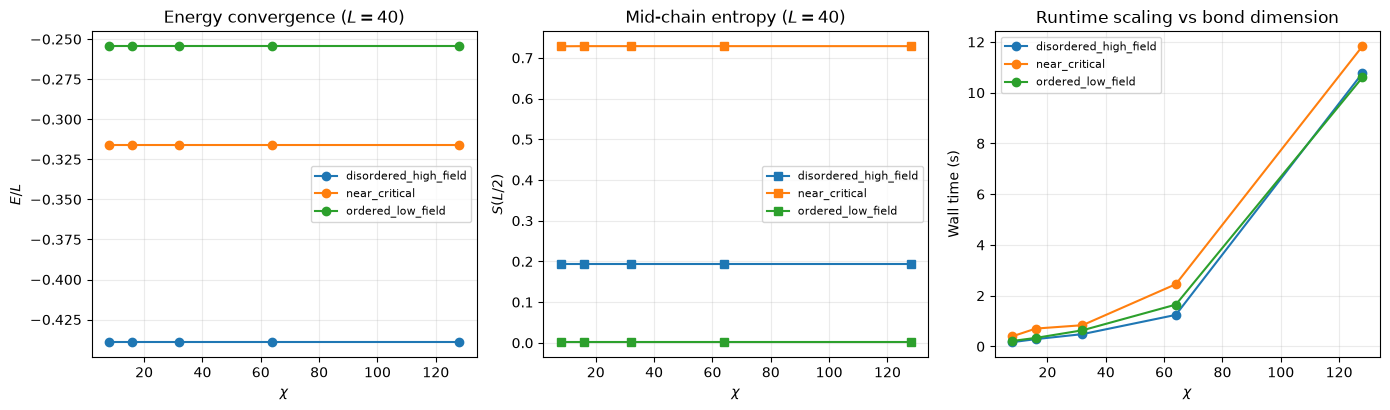

In [4]:
L_CHI = 40
CHI_VALUES = [8, 16, 32, 64, 128]
REGIMES = {"ordered_low_field": 0.20, "near_critical": 0.50, "disordered_high_field": 0.80}
chi_rows = []
for regime, g in REGIMES.items():
    for chi in CHI_VALUES:
        row, solver = run_dmrg_case(L_CHI, g, chi, max_sweeps=8, tolerance=1e-8, label=f"chi_{regime}")
        row["regime"] = regime
        if solver is not None:
            row["energy_per_site"] = float(np.real(solver.energy)) / L_CHI
            row["entropy_center"] = float(solver.state.entropy(L_CHI // 2))
        chi_rows.append(row)

chi_table = pd.DataFrame(chi_rows)
chi_table.to_csv(RESULTS / "dmrg_chi_convergence.csv", index=False)

for regime, group in chi_table[chi_table.status == "COMPLETED"].groupby("regime"):
    group = group.sort_values("chi")
    print(regime, "successive |dE/L|:", np.abs(np.diff(group.energy_per_site.to_numpy())))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for regime, group in chi_table[chi_table.status == "COMPLETED"].groupby("regime"):
    group = group.sort_values("chi")
    axes[0].plot(group.chi, group.energy_per_site, "o-", label=regime)
    axes[1].plot(group.chi, group.entropy_center, "s-", label=regime)
    axes[2].plot(group.chi, group.elapsed_seconds, "o-", label=regime)
axes[0].set(xlabel=r"$\chi$", ylabel=r"$E/L$", title=f"Energy convergence ($L={L_CHI}$)")
axes[1].set(xlabel=r"$\chi$", ylabel=r"$S(L/2)$", title=f"Mid-chain entropy ($L={L_CHI}$)")
axes[2].set(xlabel=r"$\chi$", ylabel="Wall time (s)", title="Runtime scaling vs bond dimension")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_chi_convergence.png", dpi=180)
plt.show()


 ## 5. Chain-length scaling and tested range



 The size grid evaluates $L \in \{20, 40, 60, 80, 100, 120, 160, 200\}$ at fixed $\chi=16$ across all three physical regimes. Results record elapsed wall time and post-run RSS snapshots. Reaching the configured end of this grid ($L=200$) is a tested range, not a hardware failure boundary; larger stress cases are tested separately via `limit_search.py`.

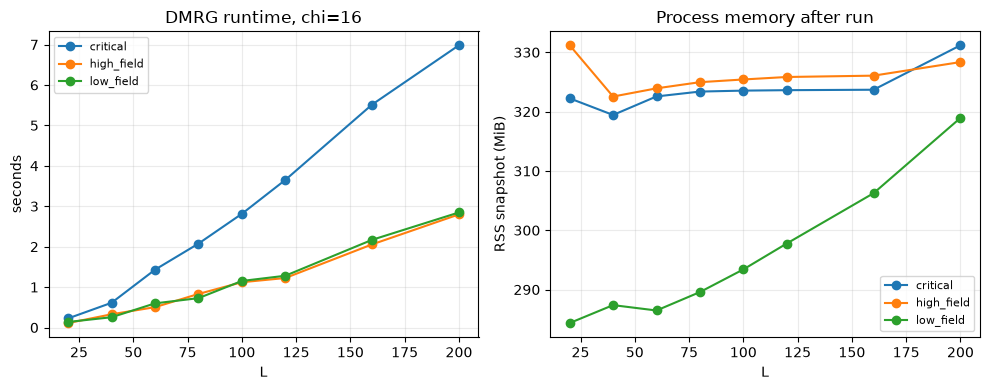

In [5]:
L_VALUES = [20, 40, 60, 80, 100, 120, 160, 200]
CHI_SIZE = 16
SIZE_FIELDS = {"low_field": 0.20, "critical": 0.50, "high_field": 0.80}
size_rows = []
for regime, g in SIZE_FIELDS.items():
    for L in L_VALUES:
        row, _ = run_dmrg_case(L, g, CHI_SIZE, max_sweeps=8, tolerance=1e-8, label=f"L_scaling_{regime}")
        row["regime"] = regime
        size_rows.append(row)

size_table = pd.DataFrame(size_rows)
size_table.to_csv(RESULTS / "dmrg_L_scaling.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for regime, group in size_table[size_table.status == "COMPLETED"].groupby("regime"):
    group = group.sort_values("L")
    axes[0].plot(group.L, group.elapsed_seconds, "o-", label=regime)
    axes[1].plot(group.L, group.rss_after_mib, "o-", label=regime)
axes[0].set(xlabel="L", ylabel="seconds", title=f"DMRG runtime, chi={CHI_SIZE}")
axes[1].set(xlabel="L", ylabel="RSS snapshot (MiB)", title="Process memory after run")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_size_scaling.png", dpi=180)
plt.show()


 ## 6. Bipartite entanglement entropy



 For $L=60$ and $\chi=64$, the notebook records the von Neumann entanglement entropy $S(l)$ across every bipartition cut $l=1,\dots,L-1$ for $g=0.20, 0.50, 0.80$, illustrating the area-law plateau off criticality versus logarithmic growth at the critical point $g_c=0.5$.

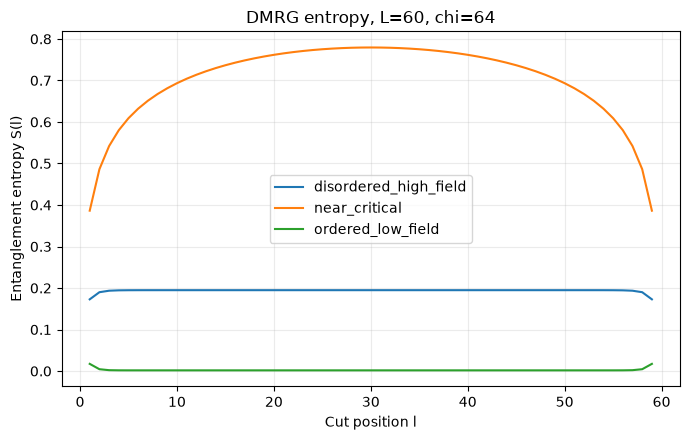

In [6]:
L_ENT = 60
CHI_ENT = 64
entropy_rows = []
for regime, g in REGIMES.items():
    row, solver = run_dmrg_case(L_ENT, g, CHI_ENT, label=f"entropy_{regime}")
    if solver is None:
        continue
    for cut in range(1, L_ENT):
        entropy_rows.append({
            "regime": regime, "g": g, "L": L_ENT, "chi": CHI_ENT,
            "cut": cut, "entropy": float(solver.state.entropy(cut)),
        })

entropy = pd.DataFrame(entropy_rows)
entropy.to_csv(RESULTS / "dmrg_entropy.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
for regime, group in entropy.groupby("regime"):
    ax.plot(group.cut, group.entropy, label=regime)
ax.set(xlabel="Cut position l", ylabel="Entanglement entropy S(l)", title=f"DMRG entropy, L={L_ENT}, chi={CHI_ENT}")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_entropy.png", dpi=180)
plt.show()


 ## 7. Correlations and fit-window dependence



 The notebook evaluates absolute two-point $Z$ correlations $|\langle Z_i Z_{i+r}\rangle|$ for $L=80$ at $\chi=64$ across $g=0.20, 0.50, 0.80$. At criticality, power-law fits for the anomalous dimension exponent $\eta$ (exact thermodynamic value $\eta=1/4$) are tested across multiple distance windows to expose finite-size window sensitivity.

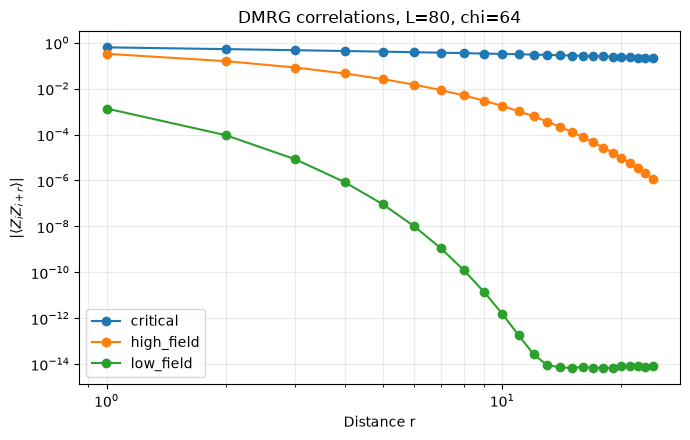

,r_min,r_max,eta_estimate,theory_eta,absolute_deviation,n_points
0,2,8,0.292046,0.25,0.042046,7
1,3,12,0.319315,0.25,0.069315,10
2,5,16,0.359643,0.25,0.109643,12


In [7]:
L_CORR = 80
CHI_CORR = 64
R_MAX = 24
CORR_FIELDS = {"low_field": 0.20, "critical": 0.50, "high_field": 0.80}
corr_rows = []
for regime, g in CORR_FIELDS.items():
    row, solver = run_dmrg_case(L_CORR, g, CHI_CORR, label=f"correlation_{regime}")
    if solver is None:
        continue
    center = L_CORR // 2
    for r in range(1, min(R_MAX, L_CORR - center - 1) + 1):
        value = solver.state.correlation(Z, center, center + r)
        corr_rows.append({
            "regime": regime, "g": g, "L": L_CORR, "chi": CHI_CORR,
            "r": r, "correlation_abs": float(abs(value)),
        })

correlations = pd.DataFrame(corr_rows)
correlations.to_csv(RESULTS / "dmrg_correlations.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
for regime, group in correlations.groupby("regime"):
    ax.loglog(group.r, group.correlation_abs, "o-", label=regime)
ax.set(xlabel="Distance r", ylabel=r"$|\langle Z_i Z_{i+r}\rangle|$", title=f"DMRG correlations, L={L_CORR}, chi={CHI_CORR}")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "dmrg_correlations.png", dpi=180)
plt.show()

critical = correlations[(correlations.regime == "critical") & (correlations.correlation_abs > 0)]
FIT_WINDOWS = [(2, 8), (3, 12), (5, 16)]
fit_rows = []
for r_min, r_max in FIT_WINDOWS:
    sub = critical[(critical.r >= r_min) & (critical.r <= r_max)]
    if len(sub) >= 3:
        slope, intercept = np.polyfit(np.log(sub.r), np.log(sub.correlation_abs), 1)
        fit_rows.append({
            "r_min": r_min, "r_max": r_max, "eta_estimate": -slope,
            "theory_eta": 0.25, "absolute_deviation": abs(-slope - 0.25),
            "n_points": len(sub),
        })
fit_table = pd.DataFrame(fit_rows)
fit_table.to_csv(RESULTS / "dmrg_eta_fit_windows.csv", index=False)
fit_table


 ## 8. Order-parameter and entanglement fits



 Diagnostic fits are performed for the critical magnetization exponent $\beta$ (exact $\beta=1/8$) and the Ising conformal central charge $c$ (exact $c=1/2$) from the critical entropy profile. Notice that finite-size symmetry restoration on open chains can suppress $|m_z|$ near $g_c$, making $\beta$ strongly sensitive to the fit window.

beta fit: 6.627838040271694 +/- 1.7427379218115553


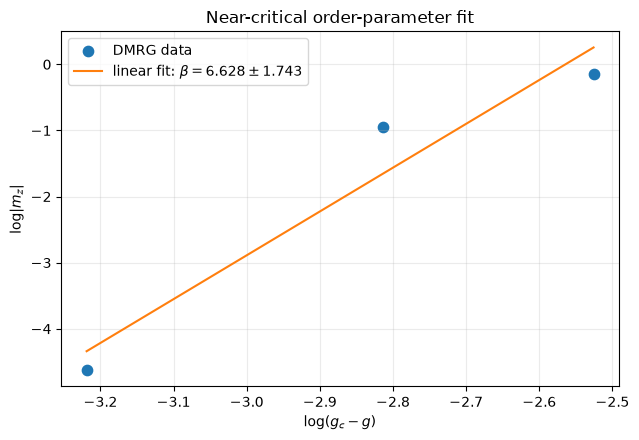

CFT central charge fit: c = 0.5183 +/- 0.0004


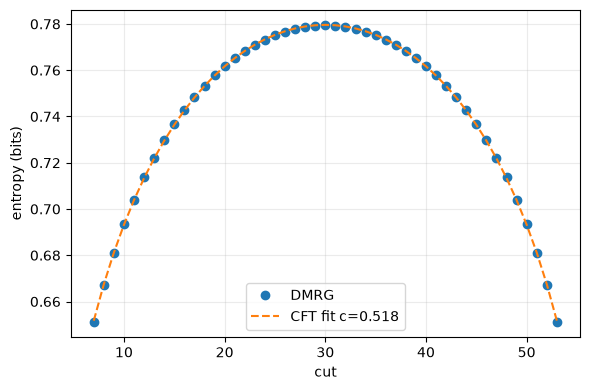

In [8]:
from scipy.stats import linregress
from scipy.optimize import curve_fit

beta_window = (0.40, 0.47)
beta_data = magnetization[
    (magnetization.status == "COMPLETED")
    & (magnetization.g > beta_window[0])
    & (magnetization.g < beta_window[1])
    & (magnetization.local_Z_center.abs() > 1e-8)
].copy()
beta_data["log_distance"] = np.log(0.5 - beta_data.g)
beta_data["log_order"] = np.log(beta_data.local_Z_center.abs())

if len(beta_data) >= 3:
    fit_beta = linregress(beta_data.log_distance, beta_data.log_order)
    pd.DataFrame([{
        "window": str(beta_window), "beta_estimate": fit_beta.slope,
        "stderr": fit_beta.stderr, "theory_beta": 1.0 / 8.0,
        "n_points": len(beta_data),
    }]).to_csv(RESULTS / "dmrg_beta_fit.csv", index=False)
    print("beta fit:", fit_beta.slope, "+/-", fit_beta.stderr)
    beta_x = np.linspace(beta_data.log_distance.min(), beta_data.log_distance.max(), 100)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.scatter(beta_data.log_distance, beta_data.log_order, s=55, label="DMRG data")
    ax.plot(beta_x, fit_beta.intercept + fit_beta.slope * beta_x, color="tab:orange",
            label=rf"linear fit: $\beta={fit_beta.slope:.3f}\pm{fit_beta.stderr:.3f}$")
    ax.set(xlabel=r"$\log(g_c-g)$", ylabel=r"$\log|m_z|$", title="Near-critical order-parameter fit")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "dmrg_beta_fit.png", dpi=220)
    plt.show()
else:
    print("Insufficient positive magnetization points for beta fit; report as inconclusive.")

critical_entropy = entropy[(entropy.regime == "near_critical") & (entropy.g == 0.5)].copy()
margin = max(1, int(L_ENT * 0.10))
critical_entropy = critical_entropy[(critical_entropy.cut > margin) & (critical_entropy.cut < L_ENT - margin)]

def cft_entropy(cut, c, offset):
    # Quimb MPS entropy is measured in bits, so use log base 2 in the Calabrese-Cardy CFT fit.
    return (c / 6.0) * np.log2((2 * L_ENT / np.pi) * np.sin(np.pi * cut / L_ENT)) + offset

if len(critical_entropy) >= 4:
    try:
        params, covariance = curve_fit(
            cft_entropy, critical_entropy.cut, critical_entropy.entropy, p0=[0.5, 0.1]
        )
        c_stderr = float(np.sqrt(np.diag(covariance))[0])
        pd.DataFrame([{
            "c_estimate": float(params[0]), "stderr": c_stderr,
            "theory_c": 0.5, "L": L_ENT, "chi": CHI_ENT, "margin": margin,
        }]).to_csv(RESULTS / "dmrg_cft_central_charge_fit.csv", index=False)
        print(f"CFT central charge fit: c = {params[0]:.4f} +/- {c_stderr:.4f}")
        plt.figure(figsize=(6, 4))
        plt.plot(critical_entropy.cut, critical_entropy.entropy, "o", label="DMRG")
        plt.plot(critical_entropy.cut, cft_entropy(critical_entropy.cut, *params), "--",
                 label=f"CFT fit c={params[0]:.3f}")
        plt.xlabel("cut")
        plt.ylabel("entropy (bits)")
        plt.grid(alpha=0.25)
        plt.legend()
        plt.tight_layout()
        plt.savefig(RESULTS / "dmrg_cft_central_charge_fit.png", dpi=220)
        plt.show()
    except RuntimeError as exc:
        print(f"CFT curve_fit did not converge: {exc}")
else:
    print("Insufficient entropy points for CFT fit; report unavailable for this size/grid.")


 ## 9. Exact-diagonalization cross-check



 Dense exact diagonalization validates ground-state energies for $L \in \{4, 6, 8, 10\}$ at $g \in \{0.20, 0.50, 0.80\}$ against DMRG at $\chi=32$ (which equals the maximum bipartite bond dimension $2^{L/2}$ up to $L=10$).

In [9]:
def exact_ground_energy(L, g, J=1.0):
    H = qtn.MPO_ham_ising(L, j=J, bx=J * g).to_dense()
    return float(np.linalg.eigvalsh(H)[0])

EXACT_SIZES = [4, 6, 8, 10]
EXACT_FIELDS = [0.20, 0.50, 0.80]
exact_rows = []
for g in EXACT_FIELDS:
    for L in EXACT_SIZES:
        exact = exact_ground_energy(L, g)
        dmrg_row, _ = run_dmrg_case(L, g, chi=32, label="exact_crosscheck")
        if dmrg_row.get("status") == "COMPLETED":
            abs_err = abs(exact - dmrg_row["energy"])
            exact_rows.append({
                "L": L, "g": g, "E_exact": exact, "E_dmrg": dmrg_row["energy"],
                "abs_error": abs_err,
                "relative_error": abs_err / max(abs(exact), 1e-14),
            })

exact_table = pd.DataFrame(exact_rows)
exact_table.to_csv(RESULTS / "dmrg_exact_crosscheck.csv", index=False)
exact_table


,L,g,E_exact,E_dmrg,abs_error,relative_error
0,4,0.2,-0.816037,-0.816037,0.000000e+00,0.000000e+00
1,6,0.2,-1.331906,-1.331906,2.898271e-09,2.176033e-09
2,8,0.2,-1.851398,-1.851398,2.042336e-08,1.103132e-08
3,10,0.2,-2.371491,-2.371491,3.396630e-08,1.432276e-08
4,4,0.5,-1.189693,-1.189693,1.110223e-15,9.332016e-16
5,6,0.5,-1.824057,-1.824057,2.914011e-09,1.597544e-09
6,8,0.5,-2.459488,-2.459488,3.577577e-08,1.454602e-08
7,10,0.5,-3.095372,-3.095372,2.905975e-09,9.388126e-10
8,4,0.8,-1.718012,-1.718012,2.220446e-16,1.292451e-16
9,6,0.8,-2.598242,-2.598242,2.654323e-09,1.021584e-09


 ## 10. Automated run summary and caveats



 The cell below summarizes all executed DMRG cases, exact cross-check errors, and diagnostic critical-exponent fits directly from the files written in `results/tutorial_faithful/`.

In [10]:
runs_summary = pd.read_csv(RESULTS / "dmrg_runs.csv")
print("dmrg_runs.csv status counts:", runs_summary.status.value_counts(dropna=False).to_dict())
print("magnetization scan status counts:", magnetization.status.value_counts(dropna=False).to_dict())
if not exact_table.empty:
    print(f"Max exact-check abs error (L<=10, chi=32): {exact_table.abs_error.max():.3e}")
if not fit_table.empty:
    print("Critical eta fit windows:\n", fit_table.to_string(index=False))

dmrg_runs.csv status counts: {'COMPLETED': 58}
magnetization scan status counts: {'COMPLETED': 51}
Max exact-check abs error (L<=10, chi=32): 3.578e-08
Critical eta fit windows:
  r_min  r_max  eta_estimate  theory_eta  absolute_deviation  n_points
     2      8      0.292046        0.25            0.042046         7
     3     12      0.319315        0.25            0.069315        10
     5     16      0.359643        0.25            0.109643        12
